In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
import warnings
warnings.filterwarnings('ignore')

# Set style for better visualizations
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)
pd.set_option('display.float_format', '{:.2f}'.format)

print("Libraries imported successfully!")


Libraries imported successfully!


In [ ]:
# Load the dataset
df = pd.read_csv("/content/banking_transaction_analysis_raw.csv")

print(f"Dataset loaded successfully!")
print(f"Shape: {df.shape}")
print(f"\nFirst 5 rows:")
df.head()

Dataset loaded successfully!
Shape: (2020, 17)

First 5 rows:


,Transaction_ID,Customer_ID,Account_ID,Transaction_Date,Transaction_Type,Amount_INR,Transaction_Fee_INR,Account_Balance_INR,Account_Type,Merchant_Category,City,Branch,Channel,Transaction_Status,Device_Type,Is_International,Customer_Age
0,TXN101569,C1039,AC20578,2025-07-19 21:04:08,Credit Card,1943.87,0.00,196385.00,Savings,Entertainment,Hyderabad,Delhi Connaught Place,POS,Successful,Web,No,48.00
1,TXN100239,C1470,AC20438,2025-10-15 08:55:58,UPI,2048.10,0.00,42123.05,Savings,Education,Lucknow,Bhopal MP Nagar,Branch,Successful,Web,No,18.00
2,TXN101414,C1588,AC20394,2025-12-16 03:08:19,ATM Withdrawal,1942.19,10.00,1251.89,Savings,Travel,Hyderabad,Indore Vijay Nagar,POS,Successful,iOS,No,21.00
3,TXN101645,C1518,AC20833,2025-12-05 17:06:57,IMPS,263.98,25.00,210861.28,Savings,Education,Jaipur,Ahmedabad Navrangpura,ATM,Successful,Web,No,37.00
4,TXN101123,C1174,AC20148,2025-01-10 12:12:51,Cash Deposit,1101.87,0.00,16429.63,Salary,Healthcare,Delhi,Lucknow Hazratganj,ATM,Successful,iOS,Yes,68.00


In [ ]:
df.tail()

,Transaction_ID,Customer_ID,Account_ID,Transaction_Date,Transaction_Type,Amount_INR,Transaction_Fee_INR,Account_Balance_INR,Account_Type,Merchant_Category,City,Branch,Channel,Transaction_Status,Device_Type,Is_International,Customer_Age
2015,TXN101571,C1153,AC20869,2025-03-04 01:28:40,NEFT,1451.57,15.00,138532.48,Savings,Groceries,Hyderabad,Delhi Connaught Place,ATM,Successful,Android,No,47.00
2016,TXN100510,C1384,AC20889,2025-04-21 21:46:19,IMPS,1523.69,5.00,170250.11,Current,Education,Mumbai,Indore Vijay Nagar,Branch,Successful,Web,No,38.00
2017,TXN100237,C1460,AC20473,2025-09-17 00:44:54,UPI,933.09,0.00,162275.20,Current,Education,Pune,Jaipur C-Scheme,Branch,Pending,Android,Yes,43.00
2018,TXN101396,C1404,AC20074,2025-10-05 08:36:13,Cheque,4491.47,NaN,244310.56,Current,Education,Jaipur,Ahmedabad Navrangpura,POS,Successful,Android,No,28.00
2019,TXN100124,C1337,AC20560,2025-11-08 17:01:15,UPI,647.11,NaN,122218.02,Salary,Entertainment,Bengaluru,Jaipur C-Scheme,Mobile App,Successful,Android,No,39.00


In [ ]:
df.describe()

,Amount_INR,Transaction_Fee_INR,Account_Balance_INR,Customer_Age
count,2020.00,1979.00,2020.00,1979.00
mean,2737.17,18.68,123531.69,45.65
std,29934.34,257.54,71631.61,16.85
min,-500.00,-10.00,747.25,-4.00
25%,602.06,0.00,61541.13,31.00
50%,1113.52,2.50,124592.44,45.00
75%,2036.95,15.00,183779.95,60.00
max,999999.00,9999.00,249915.99,150.00


In [ ]:
df.shape

(2020, 17)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2020 entries, 0 to 2019
Data columns (total 17 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Transaction_ID       2020 non-null   object 
 1   Customer_ID          2020 non-null   object 
 2   Account_ID           2020 non-null   object 
 3   Transaction_Date     2020 non-null   object 
 4   Transaction_Type     2020 non-null   object 
 5   Amount_INR           2020 non-null   float64
 6   Transaction_Fee_INR  1979 non-null   float64
 7   Account_Balance_INR  2020 non-null   float64
 8   Account_Type         1990 non-null   object 
 9   Merchant_Category    1969 non-null   object 
 10  City                 1969 non-null   object 
 11  Branch               2020 non-null   object 
 12  Channel              1978 non-null   object 
 13  Transaction_Status   1990 non-null   object 
 14  Device_Type          2020 non-null   object 
 15  Is_International     2020 non-null   o

In [ ]:
# check for missing values
print("Missing values Analysis : ")

missing_value = df.isnull().sum()
missing_percentage =(df.isnull().sum()/ len(df))*100
missing_df =pd.DataFrame({
  'Missing count' : missing_value,
  'Missing percentage' : missing_percentage
})
print(missing_df)
print(f"\nTotal missing values : {df.isnull().sum().sum()}")

Missing values Analysis : 
                     Missing count  Missing percentage
Transaction_ID                   0                0.00
Customer_ID                      0                0.00
Account_ID                       0                0.00
Transaction_Date                 0                0.00
Transaction_Type                 0                0.00
Amount_INR                       0                0.00
Transaction_Fee_INR             41                2.03
Account_Balance_INR              0                0.00
Account_Type                    30                1.49
Merchant_Category               51                2.52
City                            51                2.52
Branch                           0                0.00
Channel                         42                2.08
Transaction_Status              30                1.49
Device_Type                      0                0.00
Is_International                 0                0.00
Customer_Age                    41    

In [ ]:
df['Transaction_Fee_INR'] = df['Transaction_Fee_INR'].fillna(
    df['Transaction_Fee_INR'].median()
)

In [ ]:
df['Account_Type'] = df['Account_Type'].fillna(
    df['Account_Type'].mode()[0]
)

df['Channel'] = df['Channel'].fillna(
    df['Channel'].mode()[0]
)

df['Customer_Age'] = df['Customer_Age'].fillna(
    df['Customer_Age'].mode()[0]
)

In [ ]:
cols = [
    'Merchant_Category',
    'City',
]

df[cols] = df[cols].fillna('Unknown')

In [ ]:
cols = [
   'Transaction_Status',
]

df[cols] = df[cols].fillna('confirmed')

In [ ]:
print(df.isnull().sum())
print("Total missing values:", df.isnull().sum().sum())

Transaction_ID         0
Customer_ID            0
Account_ID             0
Transaction_Date       0
Transaction_Type       0
Amount_INR             0
Transaction_Fee_INR    0
Account_Balance_INR    0
Account_Type           0
Merchant_Category      0
City                   0
Branch                 0
Channel                0
Transaction_Status     0
Device_Type            0
Is_International       0
Customer_Age           0
dtype: int64
Total missing values: 0


In [ ]:
df.to_csv("cleaned_food_delivery_analysis.csv", index=False)

In [ ]:
df.dtypes

,0
Transaction_ID,object
Customer_ID,object
Account_ID,object
Transaction_Date,object
Transaction_Type,object
Amount_INR,float64
Transaction_Fee_INR,float64
Account_Balance_INR,float64
Account_Type,object
Merchant_Category,object


In [ ]:
df.empty

False

In [ ]:
df.duplicated().sum()

np.int64(20)

In [ ]:
df.nunique()

,0
Transaction_ID,2000
Customer_ID,574
Account_ID,813
Transaction_Date,2000
Transaction_Type,15
Amount_INR,1990
Transaction_Fee_INR,13
Account_Balance_INR,2000
Account_Type,3
Merchant_Category,18


In [ ]:
df[df['Transaction_ID'].duplicated()]

,Transaction_ID,Customer_ID,Account_ID,Transaction_Date,Transaction_Type,Amount_INR,Transaction_Fee_INR,Account_Balance_INR,Account_Type,Merchant_Category,City,Branch,Channel,Transaction_Status,Device_Type,Is_International,Customer_Age
149,TXN100871,C1297,AC20390,2025-06-10 22:29:09,Cash Deposit,592.75,0.00,28851.40,Current,Healthcare,Pune,Indore Vijay Nagar,POS,Successful,iOS,No,25.00
542,TXN100327,C1476,AC20746,2025-12-19 20:33:45,Credit Card,847.32,15.00,5880.76,Current,Education,HYDERABAD,Jaipur C-Scheme,Internet Banking,Successful,Web,No,43.00
572,TXN101902,C1022,AC20534,2025-02-25 06:43:59,Cash Deposit,2694.57,0.00,208468.87,Savings,Food & Dining,Pune,Pune Hinjewadi,ATM,Successful,iOS,No,21.00
702,TXN100614,C1598,AC20637,2025-07-23 22:17:59,ATM Withdrawal,1120.25,25.00,138042.41,Savings,Shopping,Unknown,Lucknow Hazratganj,POS,Successful,iOS,No,23.00
737,TXN101082,C1447,AC20458,2025-09-05 18:39:40,Cash Deposit,846.66,0.00,2627.22,Savings,Utilities,Indore,Lucknow Hazratganj,Branch,Successful,ATM Terminal,Yes,41.00
1216,TXN101939,C1434,AC20612,2025-05-28 11:20:51,NEFT,585.22,2.50,165680.30,Salary,Healthcare,Ahmedabad,Bhopal MP Nagar,Branch,Successful,ATM Terminal,No,36.00
1319,TXN100898,C1358,AC20281,2025-10-24 19:33:35,NEFT,1451.72,2.50,145134.33,Savings,Food & Dining,Delhi,Lucknow Hazratganj,ATM,Successful,ATM Terminal,Yes,70.00
1359,TXN100530,C1308,AC20613,2025-10-27 21:24:45,Cash Deposit,2540.92,0.00,84142.89,Current,Travel,Indore,Bhopal MP Nagar,Internet Banking,Successful,ATM Terminal,No,62.00
1508,TXN101990,C1258,AC20472,2025-09-18 06:10:20,UPI,1019.93,0.00,74919.09,Current,Utilities,Hyderabad,Jaipur C-Scheme,Mobile App,Successful,ATM Terminal,Yes,36.00
1512,TXN101776,C1017,AC20394,2025-07-28 21:26:12,IMPS,3729.20,50.00,69735.00,Salary,Entertainment,Hyderabad,Indore Vijay Nagar,ATM,Successful,Android,Yes,22.00


In [ ]:
df.drop_duplicates(subset=['Transaction_ID'], inplace=True)

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
#convert date column to datetime
df['Transaction_Date'] = pd.to_datetime(df['Transaction_Date'], errors='coerce')
print("Date column converted to datetime format.")

#Extract additional date features
df['Year']=df['Transaction_Date'].dt.year
df['Month']=df['Transaction_Date'].dt.month
df['Month_name']=df['Transaction_Date'].dt.month_name()
df['Day_of_week']=df['Transaction_Date'].dt.day_name()
df['Quarter']=df['Transaction_Date'].dt.quarter

print("Additional date features extracted : year, month, month_name, day_of_week, Quarter")


Date column converted to datetime format.
Additional date features extracted : year, month, month_name, day_of_week, Quarter


In [ ]:
df

,Transaction_ID,Customer_ID,Account_ID,Transaction_Date,Transaction_Type,Amount_INR,Transaction_Fee_INR,Account_Balance_INR,Account_Type,Merchant_Category,City,Branch,Channel,Transaction_Status,Device_Type,Is_International,Customer_Age,Year,Month,Month_name,Day_of_week,Quarter
0,TXN101569,C1039,AC20578,2025-07-19 21:04:08,Credit Card,1943.87,0.00,196385.00,Savings,Entertainment,Hyderabad,Delhi Connaught Place,POS,Successful,Web,No,48.00,2025.00,7.00,July,Saturday,3.00
1,TXN100239,C1470,AC20438,2025-10-15 08:55:58,UPI,2048.10,0.00,42123.05,Savings,Education,Lucknow,Bhopal MP Nagar,Branch,Successful,Web,No,18.00,2025.00,10.00,October,Wednesday,4.00
2,TXN101414,C1588,AC20394,2025-12-16 03:08:19,ATM Withdrawal,1942.19,10.00,1251.89,Savings,Travel,Hyderabad,Indore Vijay Nagar,POS,Successful,iOS,No,21.00,2025.00,12.00,December,Tuesday,4.00
3,TXN101645,C1518,AC20833,2025-12-05 17:06:57,IMPS,263.98,25.00,210861.28,Savings,Education,Jaipur,Ahmedabad Navrangpura,ATM,Successful,Web,No,37.00,2025.00,12.00,December,Friday,4.00
4,TXN101123,C1174,AC20148,2025-01-10 12:12:51,Cash Deposit,1101.87,0.00,16429.63,Salary,Healthcare,Delhi,Lucknow Hazratganj,ATM,Successful,iOS,Yes,68.00,2025.00,1.00,January,Friday,1.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2014,TXN100809,C1383,AC20333,2025-12-11 21:33:21,Cheque,988.37,5.00,197591.17,Current,Travel,Delhi,Lucknow Hazratganj,POS,Successful,Web,Yes,29.00,2025.00,12.00,December,Thursday,4.00
2015,TXN101571,C1153,AC20869,2025-03-04 01:28:40,NEFT,1451.57,15.00,138532.48,Savings,Groceries,Hyderabad,Delhi Connaught Place,ATM,Successful,Android,No,47.00,2025.00,3.00,March,Tuesday,1.00
2016,TXN100510,C1384,AC20889,2025-04-21 21:46:19,IMPS,1523.69,5.00,170250.11,Current,Education,Mumbai,Indore Vijay Nagar,Branch,Successful,Web,No,38.00,2025.00,4.00,April,Monday,2.00
2017,TXN100237,C1460,AC20473,2025-09-17 00:44:54,UPI,933.09,0.00,162275.20,Current,Education,Pune,Jaipur C-Scheme,Branch,Pending,Android,Yes,43.00,2025.00,9.00,September,Wednesday,3.00


In [ ]:
# Transaction type analysis
print(df["Transaction_Type"].value_counts())

# Transaction status
print(df["Transaction_Status"].value_counts())

# Total transaction amount
print(df["Amount_INR"].sum())

# Average transaction amount
print(df["Amount_INR"].mean())

# City-wise transactions
print(df.groupby("City")["Amount_INR"].sum())

Transaction_Type
Cheque            270
Cash Deposit      266
ATM Withdrawal    259
IMPS              254
UPI               246
Debit Card        232
Credit Card       227
NEFT              211
upi                 9
cash deposit        8
credit card         6
atm withdrawal      4
imps                4
cheque              3
debit card          1
Name: count, dtype: int64
Transaction_Status
Successful    1733
Failed         126
Pending         56
Reversed        55
confirmed       30
Name: count, dtype: int64
5502069.529999999
2751.034765
City
 AHMEDABAD       2510.99
 BENGALURU        579.41
 BHOPAL         10120.68
 HYDERABAD       4122.51
 INDORE          5209.03
 JAIPUR          6053.08
 LUCKNOW         4730.18
 MUMBAI          3825.04
 NAGPUR          1063.65
 PUNE            1450.59
 SURAT           1831.64
Ahmedabad      255274.19
Bengaluru      249407.66
Bhopal         259026.48
Delhi          232593.41
Hyderabad     1276461.21
Indore         301685.13
Jaipur         786201.74
Lu

# **TRANSACTION PERFORMANCE ANALYSIS ➖**

In [ ]:
#KPIs

# Total transactions
total_transactions = df["Transaction_ID"].nunique()

# Total transaction value
total_value = df["Amount_INR"].sum()

# Average transaction value
avg_transaction = df["Amount_INR"].mean()

# Unique customers
unique_customers = df["Customer_ID"].nunique()

# Successful transactions
successful = (
    df["Transaction_Status"] == "Successful"
).sum()

# Failed transactions
failed = (
    df["Transaction_Status"] == "Failed"
).sum()

# Success rate
success_rate = successful / len(df) * 100

# Failure rate
failure_rate = failed / len(df) * 100

# Total transaction fees
total_fees = df["Transaction_Fee_INR"].sum()

# International transaction value
international_value = df.loc[
    df["Is_International"] == "Yes",
    "Amount_INR"
].sum()

# Repeat customers
repeat_customers = (
    df.groupby("Customer_ID")["Transaction_ID"]
    .nunique()
    .gt(1).sum()
)

transaction_kpis = {
    "Total Transactions": total_transactions,
    "Total Transaction Value": total_value,
    "Average Transaction": avg_transaction,
    "Unique Customers": unique_customers,
    "Success Rate": round(success_rate, 2),
    "Failure Rate": round(failure_rate, 2),
    "Total Fees": total_fees,
    "International Value": international_value,
    "Repeat Customers": repeat_customers
}

kpi_df = pd.DataFrame(
    transaction_kpis.items(),
    columns=["Transactional KPI", "Value"]
)

kpi_df

,Transactional KPI,Value
0,Total Transactions,2000.00
1,Total Transaction Value,5502069.53
2,Average Transaction,2751.03
3,Unique Customers,574.00
4,Success Rate,86.65
5,Failure Rate,6.30
6,Total Fees,36858.00
7,International Value,1554098.16
8,Repeat Customers,502.00


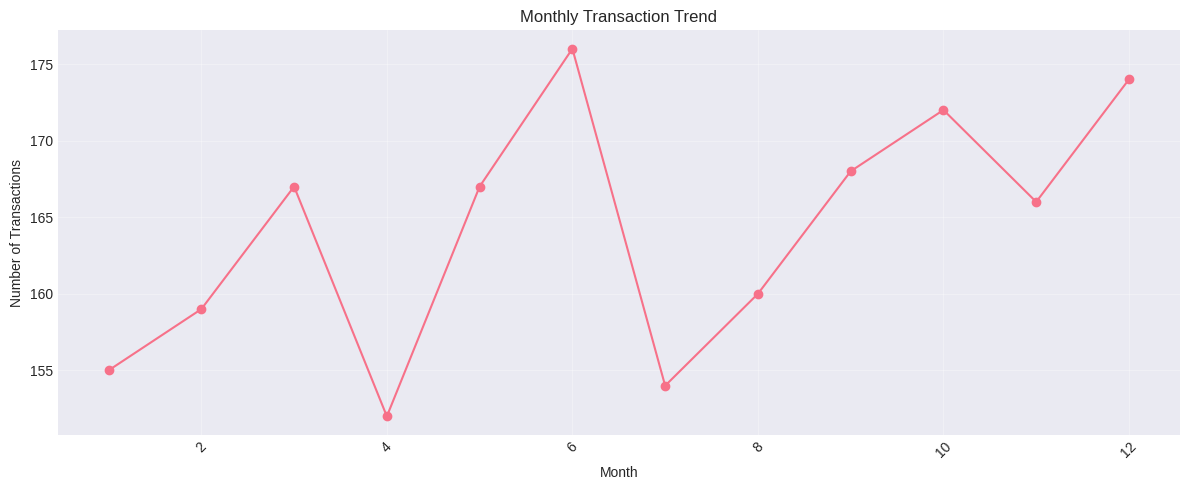

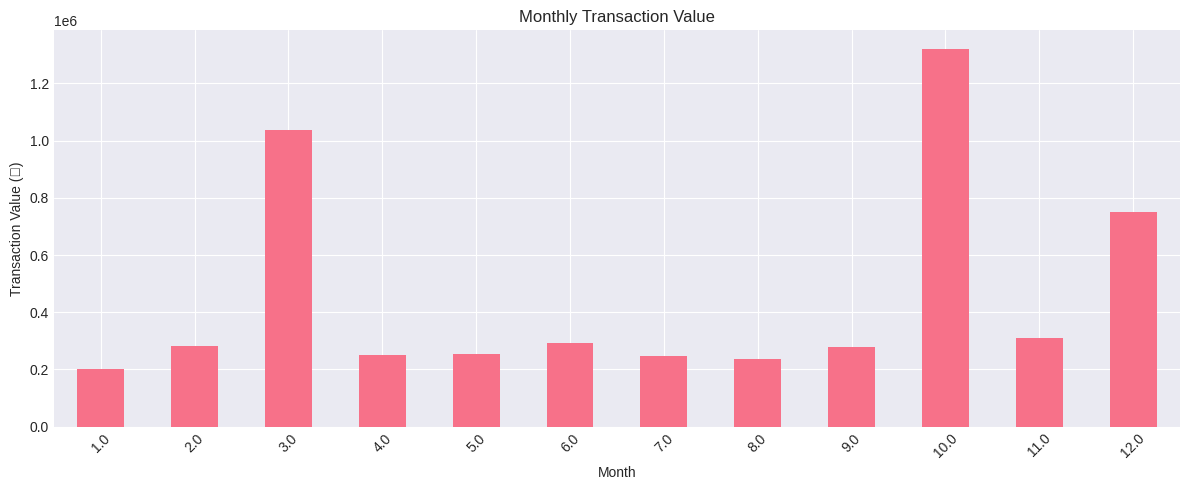

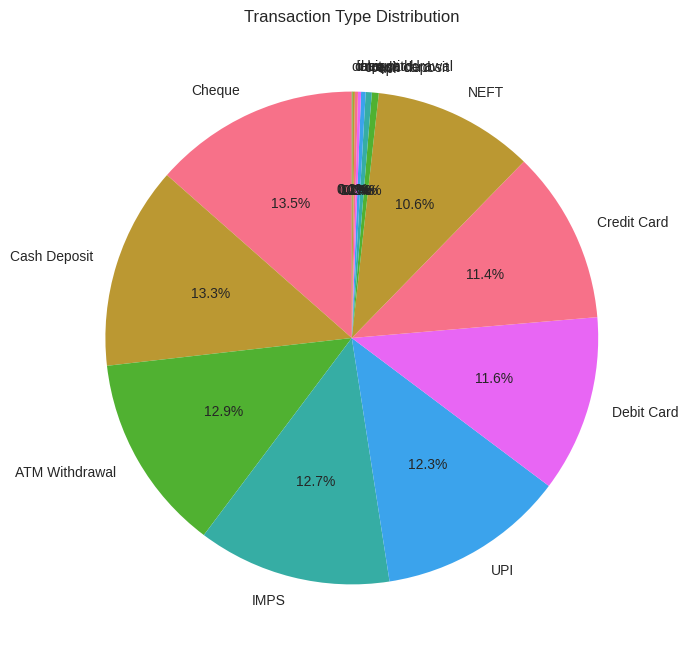

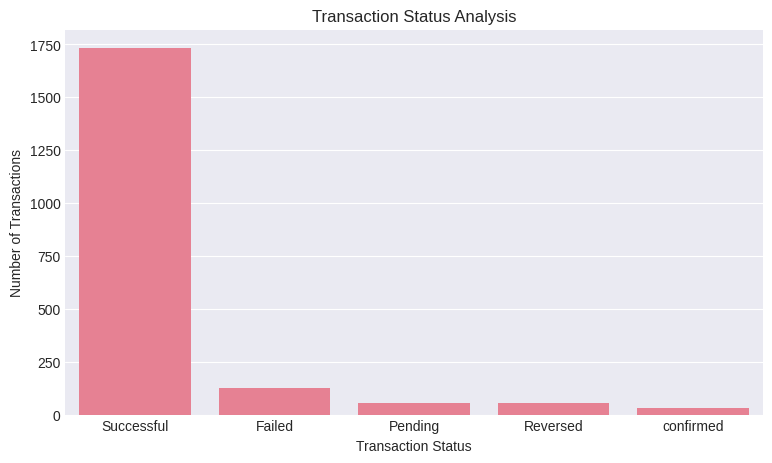

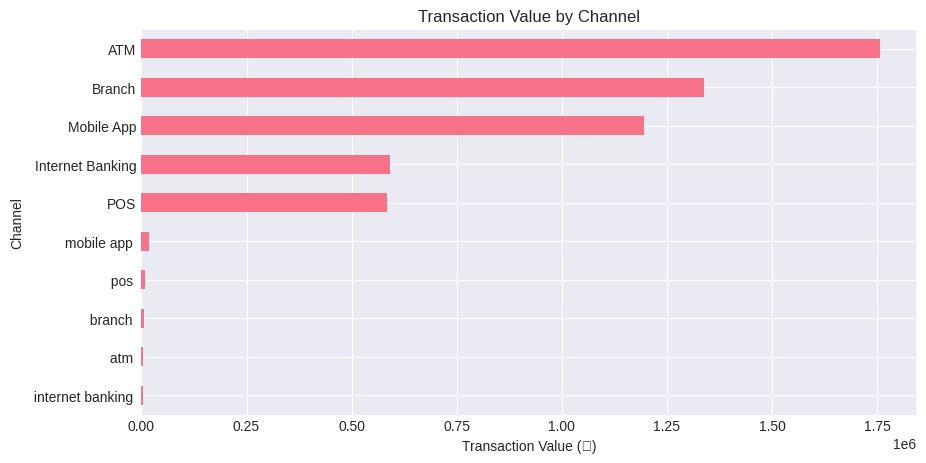

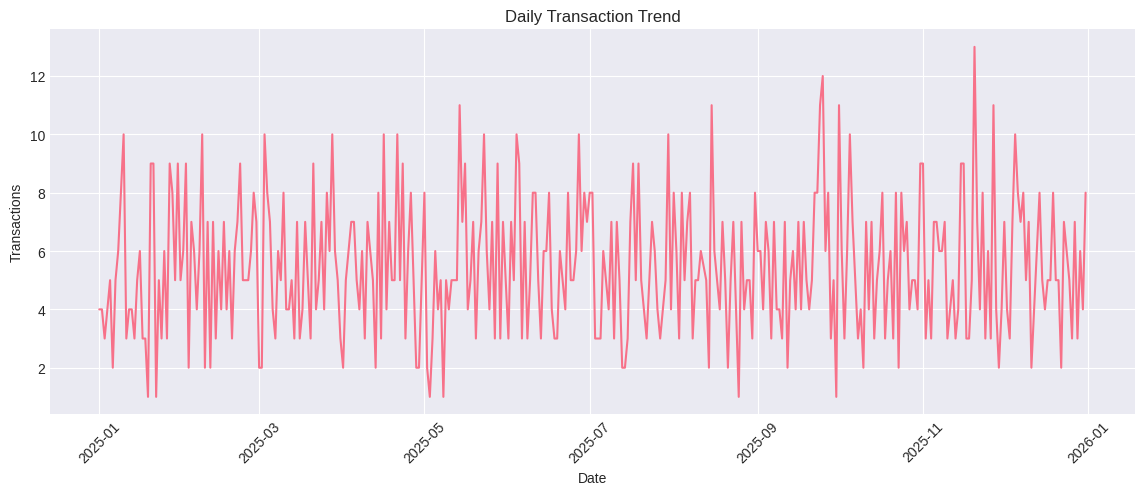

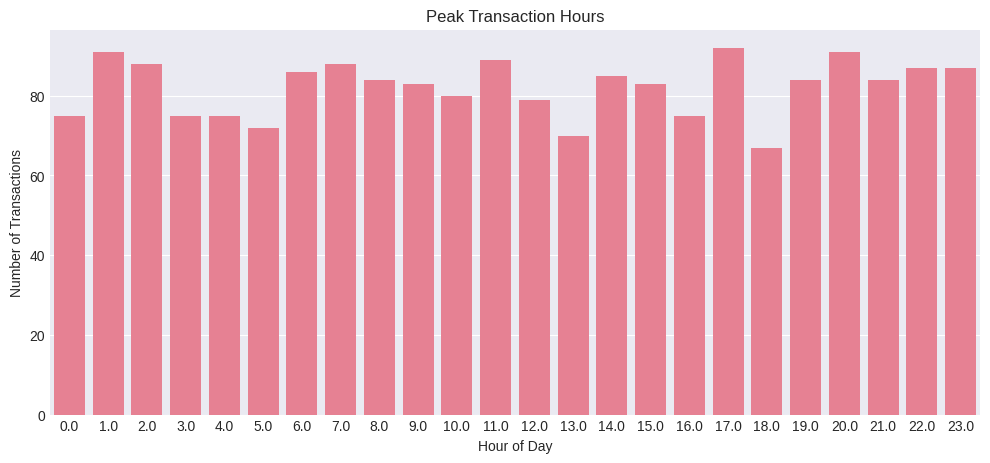

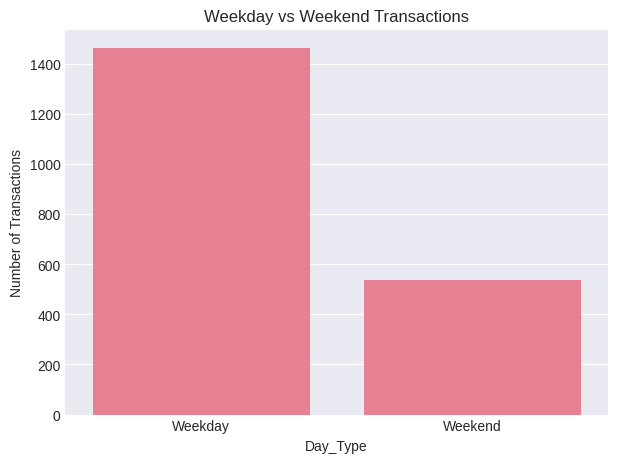

In [ ]:
#MONTHLY TRANSACTIONS TREND :--
monthly = df.groupby("Month").size()

plt.figure(figsize=(12,5))
plt.plot(monthly.index, monthly.values, marker="o")

plt.title("Monthly Transaction Trend")
plt.xlabel("Month")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#MONTHLY TRANSACTION VALUE :--
monthly_value = df.groupby("Month")["Amount_INR"].sum()

plt.figure(figsize=(12,5))
monthly_value.plot(kind="bar")

plt.title("Monthly Transaction Value")
plt.xlabel("Month")
plt.ylabel("Transaction Value (₹)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#TRANSACTION TYPE ANALYSIS
type_count = df["Transaction_Type"].value_counts()

plt.figure(figsize=(8,8))
plt.pie(
    type_count,
    labels=type_count.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Transaction Type Distribution")
plt.show()

#TRANSACTION STATUS ANALYSIS :--
status = df["Transaction_Status"].value_counts()

plt.figure(figsize=(9,5))
sns.barplot(x=status.index, y=status.values)

plt.title("Transaction Status Analysis")
plt.xlabel("Transaction Status")
plt.ylabel("Number of Transactions")
plt.show()

#TRANSACTION VALUE BY CHANNEL :---
channel = df.groupby("Channel").agg(
    Transactions=("Transaction_ID", "nunique"),
    Total_Value=("Amount_INR", "sum")
)

channel["Total_Value"].sort_values().plot(
    kind="barh", figsize=(10,5)
)

plt.title("Transaction Value by Channel")
plt.xlabel("Transaction Value (₹)")
plt.show()

#DAILY TRANSACTION TREND :--
daily = df.groupby(
    df["Transaction_Date"].dt.date
).size()

plt.figure(figsize=(14,5))
plt.plot(daily.index, daily.values)

plt.title("Daily Transaction Trend")
plt.xlabel("Date")
plt.ylabel("Transactions")
plt.xticks(rotation=45)
plt.show()

#PEAK TRANSACTION HOURS :--
df["Hour"] = df["Transaction_Date"].dt.hour
hourly = df.groupby("Hour").size()

plt.figure(figsize=(12,5))
sns.barplot(x=hourly.index, y=hourly.values)

plt.title("Peak Transaction Hours")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Transactions")
plt.show()

#WEEKDAY vs WEEKEND TRANSACTIONS :--
df["Day_Type"] = np.where(
    df["Transaction_Date"].dt.dayofweek >= 5,
    "Weekend",
    "Weekday"
)

day_analysis = df.groupby("Day_Type").size()

plt.figure(figsize=(7,5))
sns.barplot(
    x=day_analysis.index,
    y=day_analysis.values
)

plt.title("Weekday vs Weekend Transactions")
plt.ylabel("Number of Transactions")
plt.show()

# **FINANCIAL PERFORMANCE ANALYSIS**

In [ ]:
#KPIs
# Successful transactions
success = df[
    (df["Transaction_Status"].str.lower() == "successful") &
    (df["Amount_INR"] > 0)
].copy()

total_value = success["Amount_INR"].sum()
total_fees = success["Transaction_Fee_INR"].sum()

deposit = success[
    success["Transaction_Type"].str.lower() == "cash deposit"
]

withdrawal = success[
    success["Transaction_Type"].str.lower() == "atm withdrawal"
]

high_value = success[success["Amount_INR"] > 50000]

financial_kpis = {
    "Total Transaction Value": total_value,
    "Average Transaction Value": success["Amount_INR"].mean(),
    "Median Transaction Value": success["Amount_INR"].median(),
    "Maximum Transaction Value": success["Amount_INR"].max(),
    "Minimum Transaction Value": success["Amount_INR"].min(),
    "Total Deposit Value": deposit["Amount_INR"].sum(),
    "Total Withdrawal Value": withdrawal["Amount_INR"].sum(),
    "Deposit-Withdrawal Difference":
        deposit["Amount_INR"].sum() - withdrawal["Amount_INR"].sum(),
    "Total Transaction Fees": total_fees,
    "Average Transaction Fee": success["Transaction_Fee_INR"].mean(),
    "Fee-to-Value Ratio (%)":
        (total_fees / total_value * 100) if total_value else 0,
    "High-Value Transaction Amount": high_value["Amount_INR"].sum(),
    "High-Value Contribution (%)":
        (high_value["Amount_INR"].sum() / total_value * 100)
        if total_value else 0
}

kpi_df = pd.DataFrame(
    financial_kpis.items(),
    columns=["Financial KPI", "Value"]
)

kpi_df

,Financial KPI,Value
0,Total Transaction Value,5028614.17
1,Average Transaction Value,2906.71
2,Median Transaction Value,1114.44
3,Maximum Transaction Value,999999.00
4,Minimum Transaction Value,72.40
5,Total Deposit Value,355394.02
6,Total Withdrawal Value,826128.50
7,Deposit-Withdrawal Difference,-470734.48
8,Total Transaction Fees,21689.00
9,Average Transaction Fee,12.54


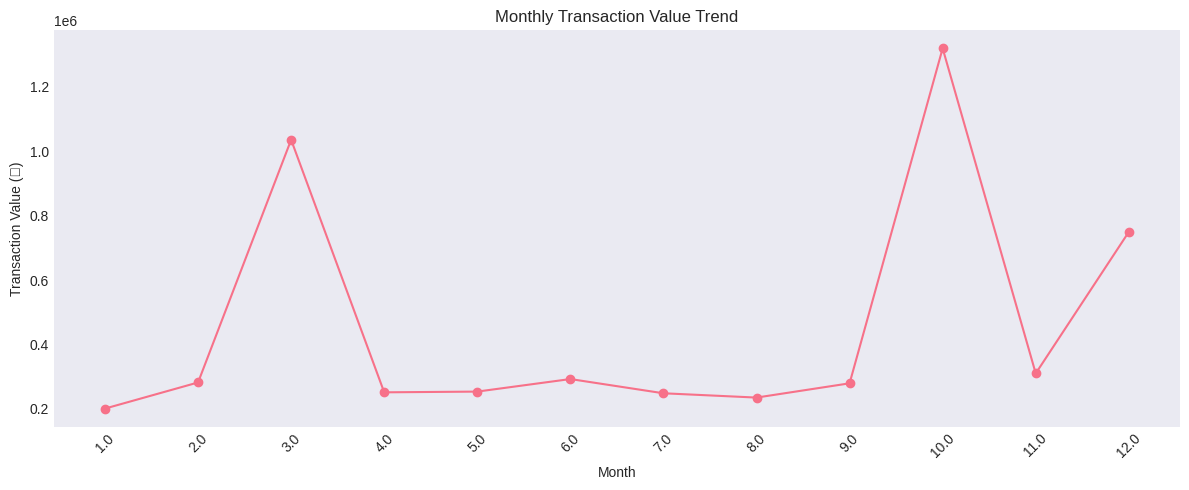

In [ ]:
monthly_sales = (
    df.groupby("Month")["Amount_INR"]
    .sum()
)

plt.figure(figsize=(12, 5))
plt.plot(
    monthly_sales.index.astype(str),
    monthly_sales.values,
    marker="o"
)

plt.title("Monthly Transaction Value Trend")
plt.xlabel("Month")
plt.ylabel("Transaction Value (₹)")
plt.xticks(rotation=45)
plt.grid()
plt.tight_layout()
plt.show()

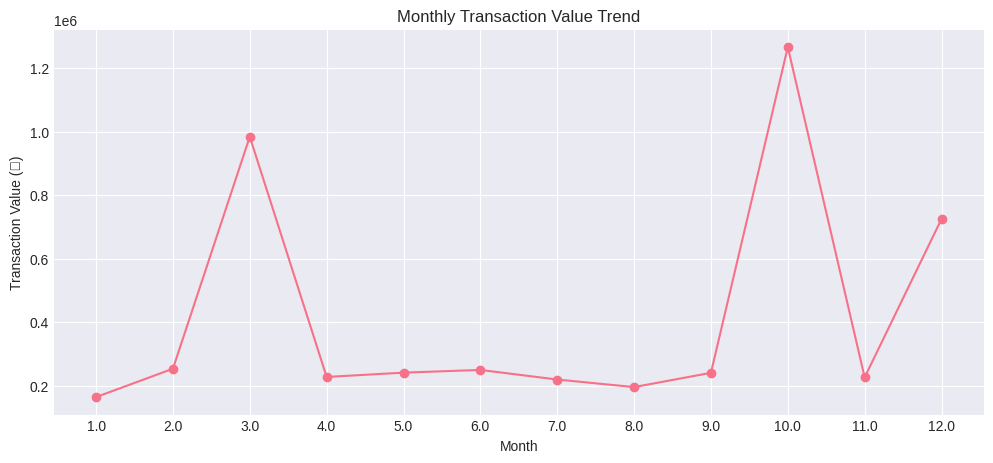

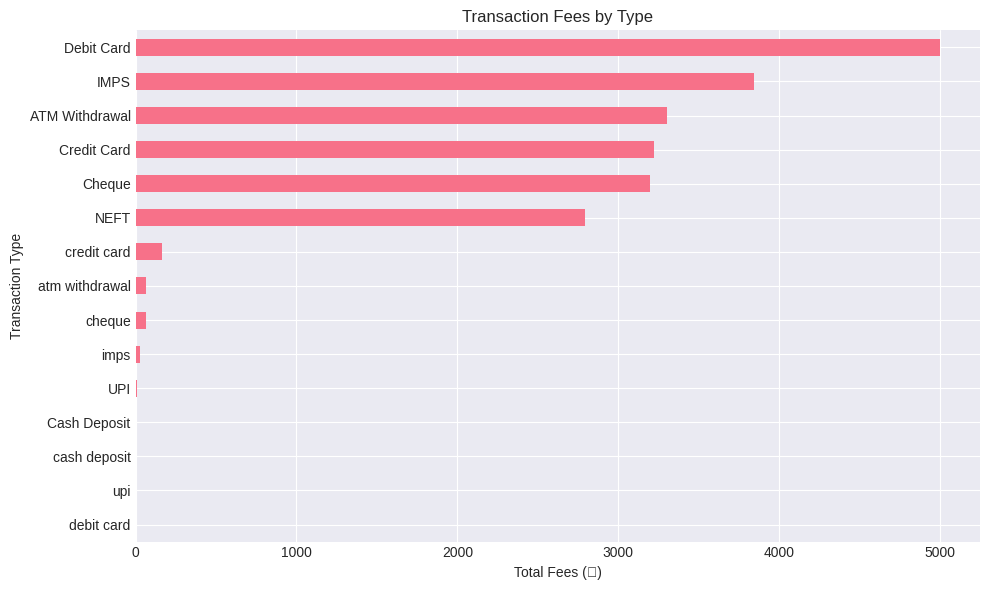

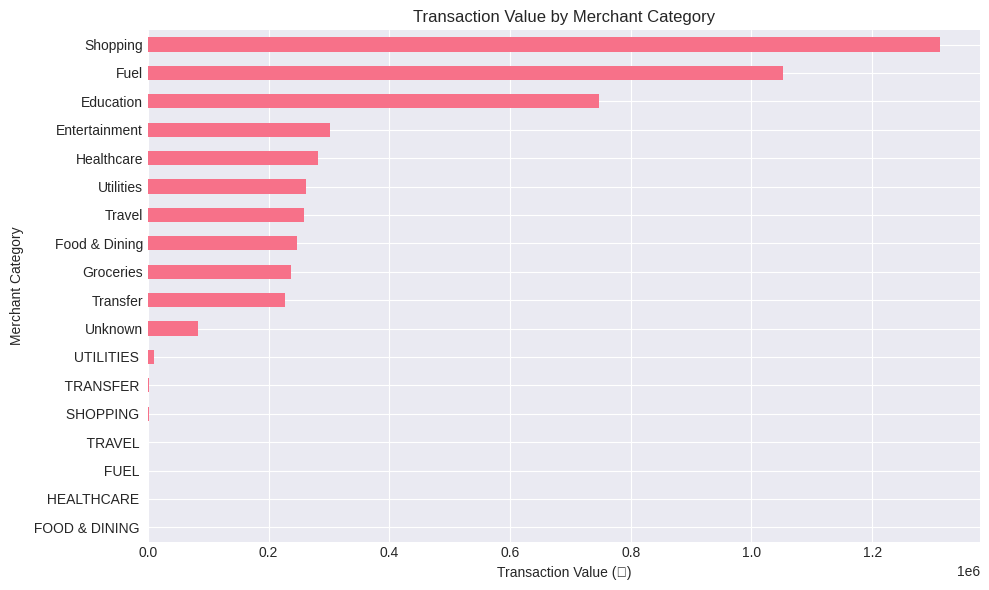

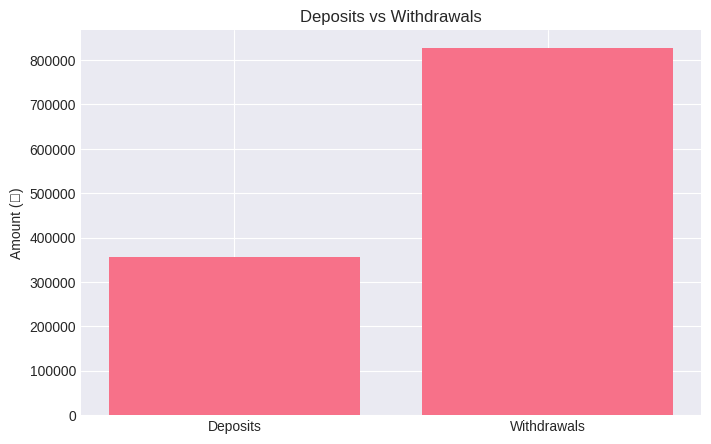

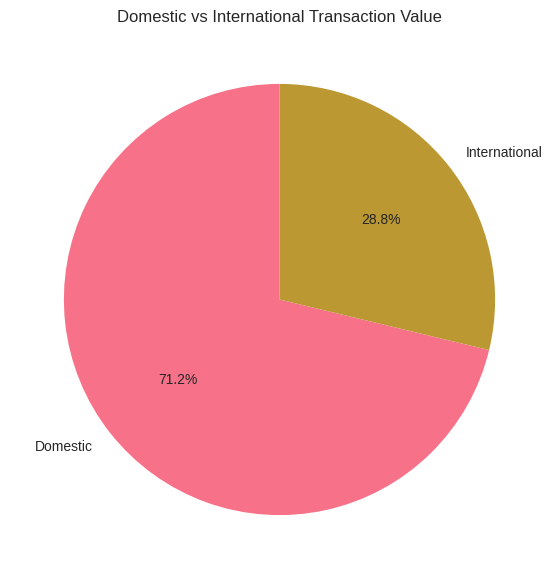

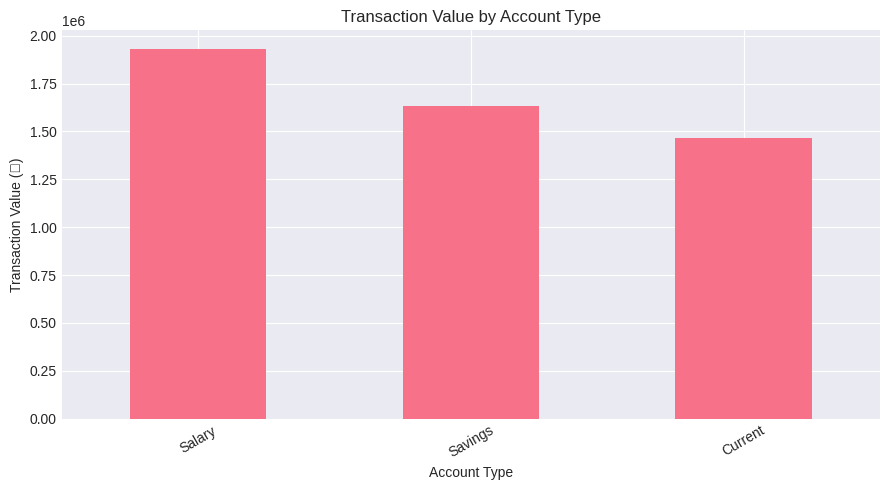

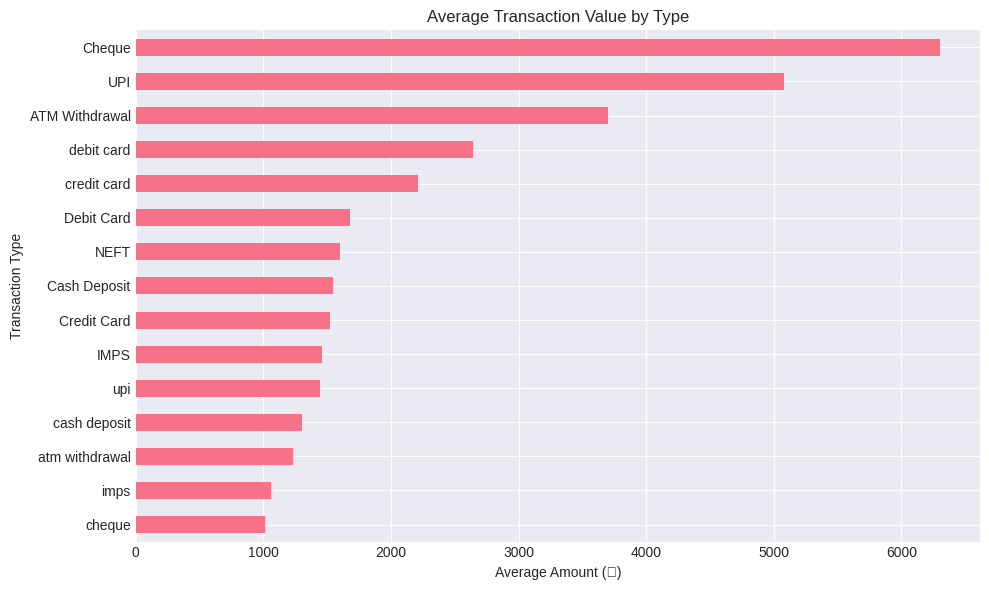

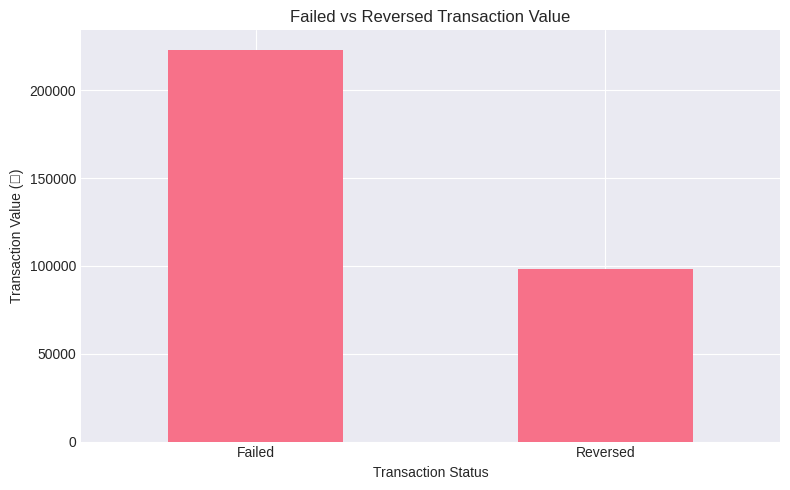

In [ ]:
#MONTHLY TRANSACTION TREND
monthly = success.groupby("Month")["Amount_INR"].sum()

plt.figure(figsize=(12,5))
plt.plot(monthly.index.astype(str), monthly.values, marker="o")

plt.title("Monthly Transaction Value Trend")
plt.xlabel("Month")
plt.ylabel("Transaction Value (₹)")
plt.show()

#TRANSACTION FEES BY TYPE
fee_type = success.groupby(
    "Transaction_Type"
)["Transaction_Fee_INR"].sum().sort_values()

fee_type.plot(kind="barh", figsize=(10,6))

plt.title("Transaction Fees by Type")
plt.xlabel("Total Fees (₹)")
plt.ylabel("Transaction Type")
plt.tight_layout()
plt.show()

# TRANSACTION AMOUNT BY MERCHANT
merchant_value = success.groupby(
    "Merchant_Category"
)["Amount_INR"].sum().sort_values()

merchant_value.plot(kind="barh", figsize=(10,6))

plt.title("Transaction Value by Merchant Category")
plt.xlabel("Transaction Value (₹)")
plt.ylabel("Merchant Category")
plt.tight_layout()
plt.show()

#DEPOSITS vs WITHDRAWL
deposit = success[
    success["Transaction_Type"].str.lower() == "cash deposit"
]["Amount_INR"].sum()

withdrawal = success[
    success["Transaction_Type"].str.lower() == "atm withdrawal"
]["Amount_INR"].sum()

plt.figure(figsize=(8,5))
plt.bar(["Deposits", "Withdrawals"], [deposit, withdrawal])

plt.title("Deposits vs Withdrawals")
plt.ylabel("Amount (₹)")
plt.show()

#DOMESTICS vs INTERNATIONAL TRANSACTIONS
international = (
    success["Is_International"]
    .astype("string").str.strip().str.lower()
    .isin(["true", "1", "yes"])
)

success["Transaction_Region"] = np.where(
    international, "International", "Domestic"
)

region_value = success.groupby(
    "Transaction_Region"
)["Amount_INR"].sum()

plt.figure(figsize=(7,7))
plt.pie(
    region_value,
    labels=region_value.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Domestic vs International Transaction Value")
plt.show()

#TRANSACTION AMOUNT BY ACCOUNT TYPE
account_value = success.groupby(
    "Account_Type"
)["Amount_INR"].sum().sort_values(ascending=False)

account_value.plot(kind="bar", figsize=(9,5))

plt.title("Transaction Value by Account Type")
plt.xlabel("Account Type")
plt.ylabel("Transaction Value (₹)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

#AVERAGE TRANSACTION VALUE TREND
avg_type = success.groupby(
    "Transaction_Type"
)["Amount_INR"].mean().sort_values()

avg_type.plot(kind="barh", figsize=(10,6))

plt.title("Average Transaction Value by Type")
plt.xlabel("Average Amount (₹)")
plt.ylabel("Transaction Type")
plt.tight_layout()
plt.show()

#FAILED vs REVERSED TRANSACTION
unsuccessful = df[
    df["Transaction_Status"].str.lower().isin(
        ["failed", "reversed"]
    ) &
    (df["Amount_INR"] > 0)
].copy()

status_value = unsuccessful.groupby(
    unsuccessful["Transaction_Status"].str.title()
)["Amount_INR"].sum()

status_value.plot(kind="bar", figsize=(8,5))

plt.title("Failed vs Reversed Transaction Value")
plt.xlabel("Transaction Status")
plt.ylabel("Transaction Value (₹)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# **CUSTOMER BEHAVIOUR ANALYSIS **

In [ ]:
# Filter successful transactions
success = df[
    (df["Transaction_Status"].str.lower() == "successful") &
    (df["Amount_INR"] > 0)
].copy()

# Customer-level summary
customer_summary = success.groupby("Customer_ID").agg(
    Total_Transactions=("Transaction_ID", "nunique"),
    Total_Transaction_Value=("Amount_INR", "sum"),
    Average_Transaction_Value=("Amount_INR", "mean"),
    Total_Fees=("Transaction_Fee_INR", "sum")
).reset_index()

# Customer KPIs
total_customers = df["Customer_ID"].nunique()
active_customers = success["Customer_ID"].nunique()

repeat_customers = (
    customer_summary["Total_Transactions"] > 1
).sum()

customer_kpis = {
    "Total Customers": total_customers,
    "Active Customers": active_customers,
    "Repeat Customers": repeat_customers,
    "Repeat Customer Rate (%)":
        repeat_customers / active_customers * 100
        if active_customers else 0,
    "Total Customer Transaction Value":
        success["Amount_INR"].sum(),
    "Average Value per Customer":
        customer_summary["Total_Transaction_Value"].mean(),
    "Average Transactions per Customer":
        customer_summary["Total_Transactions"].mean(),
    "Top Customer Transaction Value":
        customer_summary["Total_Transaction_Value"].max()
}

pd.DataFrame(
    customer_kpis.items(),
    columns=["Customer KPI", "Value"]
)

,Customer KPI,Value
0,Total Customers,574.00
1,Active Customers,563.00
2,Repeat Customers,467.00
3,Repeat Customer Rate (%),82.95
4,Total Customer Transaction Value,5028614.17
5,Average Value per Customer,8931.82
6,Average Transactions per Customer,3.07
7,Top Customer Transaction Value,1011610.27


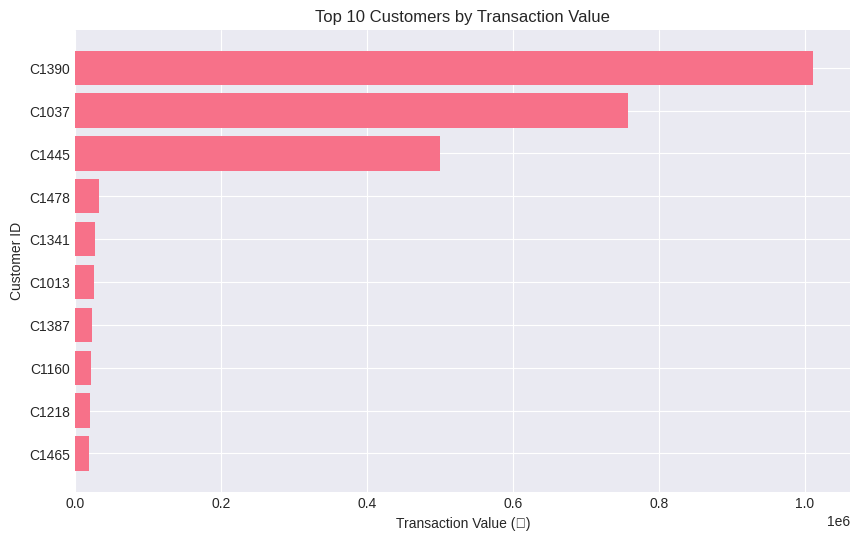

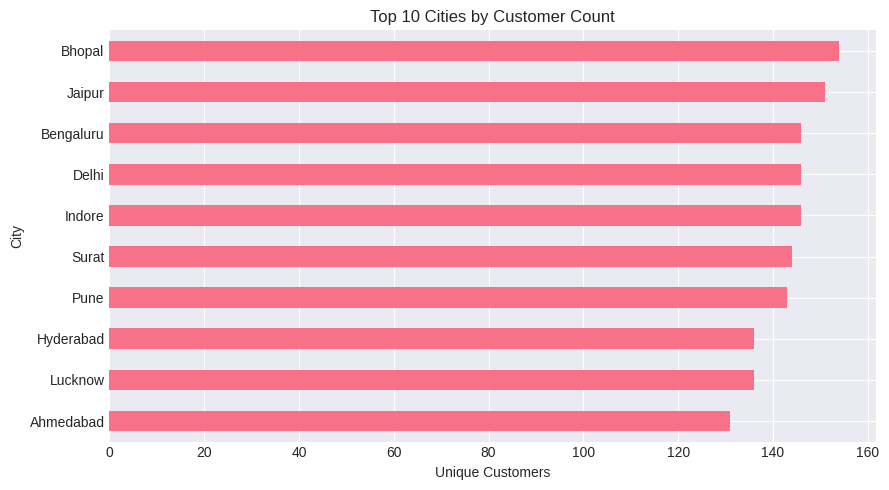

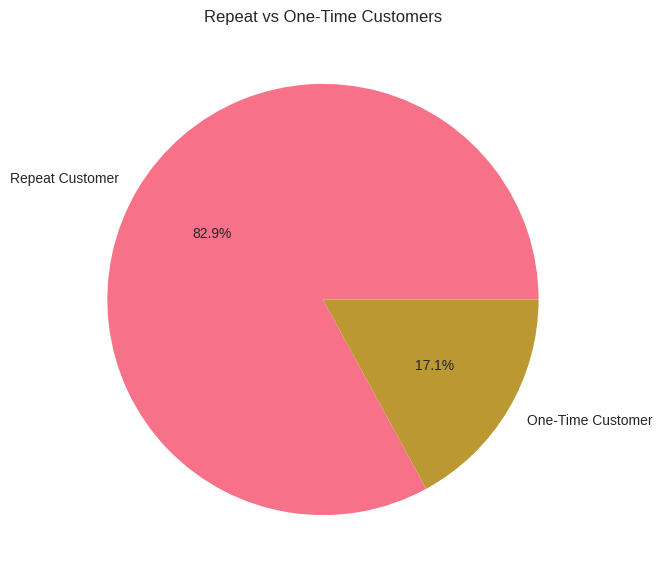

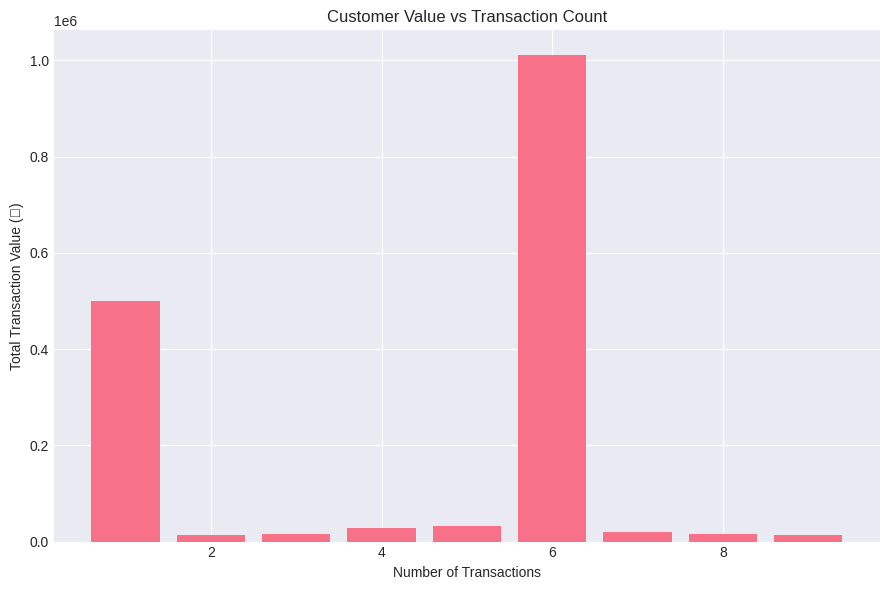

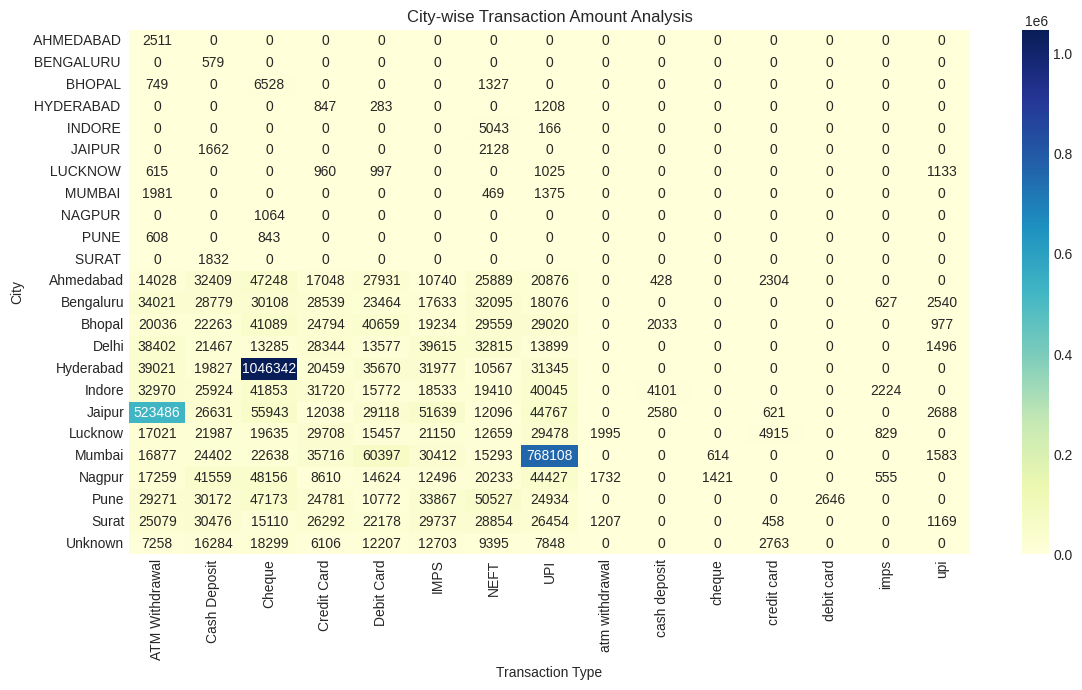

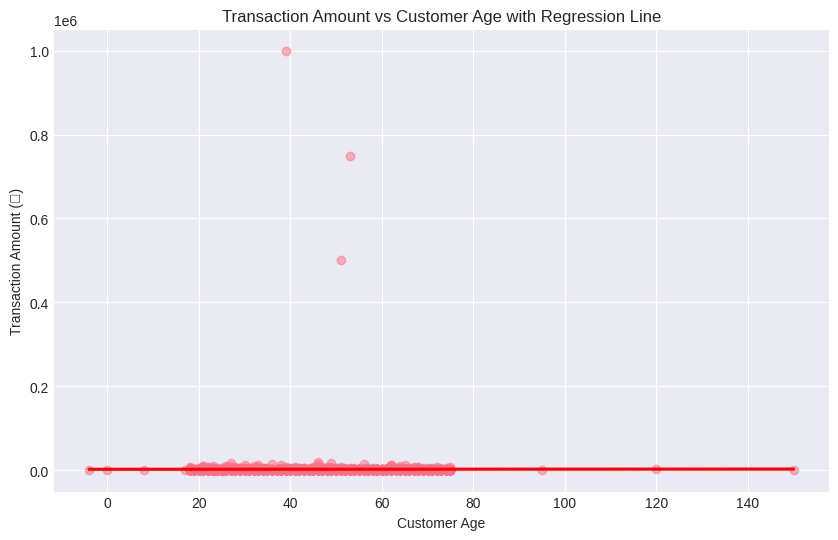

In [ ]:
#TOP 10 CUSTOMERS
top_10_customers = customer_summary.sort_values(
    by="Total_Transaction_Value",
    ascending=False
).head(10)

plt.figure(figsize=(10,6))

plt.barh(
    top_10_customers["Customer_ID"].astype(str),
    top_10_customers["Total_Transaction_Value"]
)

plt.title("Top 10 Customers by Transaction Value")
plt.xlabel("Transaction Value (₹)")
plt.ylabel("Customer ID")
plt.gca().invert_yaxis()
plt.show()

#CUSTOMER DISTRIBUTION BY CITY
city_customers = df.groupby("City")[
    "Customer_ID"
].nunique().sort_values(ascending=False).head(10)

city_customers.plot(kind="barh", figsize=(9,5))

plt.title("Top 10 Cities by Customer Count")
plt.xlabel("Unique Customers")
plt.ylabel("City")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

#REPEAT vs ONE-TIME CUSTOMER
customer_type = np.where(customer_summary["Total_Transactions"] > 1,
    "Repeat Customer",
    "One-Time Customer"
)

pd.Series(customer_type).value_counts().plot(
    kind="pie",
    autopct="%1.1f%%",
    figsize=(7,7)
)

plt.title("Repeat vs One-Time Customers")
plt.ylabel("")
plt.show()

#CUSTOMER vs TRANSACTIONS
plt.figure(figsize=(9,6))

plt.bar(
    customer_summary["Total_Transactions"],
    customer_summary["Total_Transaction_Value"]
)

plt.title("Customer Value vs Transaction Count")
plt.xlabel("Number of Transactions")
plt.ylabel("Total Transaction Value (₹)")
plt.tight_layout()
plt.show()

#CITY-WISE TRANSACTION AMOUNT ANALYSIS
city_amount = success.pivot_table(
    index="City",
    columns="Transaction_Type",
    values="Amount_INR",
    aggfunc="sum",
    fill_value=0
)

plt.figure(figsize=(12, 7))
sns.heatmap(city_amount, annot=True, fmt=".0f", cmap="YlGnBu")

plt.title("City-wise Transaction Amount Analysis")
plt.xlabel("Transaction Type")
plt.ylabel("City")
plt.tight_layout()
plt.show()

#TRANSACTION AMOUNT VS CUSTOMER AGE
plt.figure(figsize=(10, 6))
sns.regplot(
    data=df,
    x="Customer_Age",
    y="Amount_INR",
    scatter_kws={"alpha":0.5},
    line_kws={"color": "red"}
)

plt.title("Transaction Amount vs Customer Age with Regression Line")
plt.xlabel("Customer Age")
plt.ylabel("Transaction Amount (₹)")
plt.show()

The Banking Transaction Analysis project successfully demonstrates how Python can be used to analyze banking transaction data and generate meaningful business insights. Using Pandas, NumPy, Matplotlib, and Seaborn, the project covered data cleaning, exploratory data analysis, KPI development, customer segmentation, financial performance evaluation, and transaction risk analysis.

The analysis provides a structured understanding of transaction trends, customer behaviour, financial activities, and banking channel performance. It also helps identify unusual transaction patterns, failed transactions, high-value customers, and opportunities to improve operational efficiency.

The key business value of this project is its ability to transform raw banking data into actionable information that supports better decision-making.

Key outcomes of the project:
1. Improved understanding of banking transaction patterns and financial performance.
2. Identification of valuable customer segments and repeat customer behaviour.
3. Evaluation of transaction success rates and banking channel utilization.
4. Identification of unusual transaction activities for further risk investigation.
5. Development of data-driven recommendations to improve customer experience and operational efficiency.
Final conclusion:

This project strengthened my practical knowledge of Python-based data analytics and demonstrated how data-driven insights can support strategic decisions in the banking and financial services industry. It also provided hands-on experience in solving real-world business problems through data analysis and visualization.